
# PlantSegV2 — FINAL Test-Set Baseline Comparison for PhytoFactor-HPCTR v2

This notebook is the **final controlled baseline experiment** aligned to the
executed PhytoFactor-HPCTR v2 notebook.

## Non-negotiable evaluation protocol

- **Training:** `train` split only.
- **Model selection / early stopping:** `val` split only.
- **Final reported baseline result:** **untouched `test` split only**.
- **Seed:** `42`, matching the original HPCTR v2 run.
- **Primary inference:** single-view EMA, matching the HPCTR v2 primary result.
- The test set is evaluated **once after the best validation-selected checkpoint
  has been loaded**. It is never used for training, early stopping, or checkpoint selection.

## Baselines

1. ResNet50-U-Net-HierMTL
2. DeepLabV3+-ResNet50-HierMTL
3. Swin-T-FPN-HierMTL
4. ConvNeXt-Tiny-FPN-HierMTL — the key backbone-matched control

All baselines use the same PlantSegV2 taxonomy, 512×512 input resolution,
batch size 2 with gradient accumulation 2, augmentation family, long-tail
weights, hierarchical classification supervision, segmentation loss family,
coverage target, AdamW schedule, EMA selection, and evaluation definitions
used by the main experiment wherever those components are architecture-independent.

The proposed-only mechanisms — prototype memory, prototype loss, HPCTR routing,
directed cross-task messages, and routed severity context — are intentionally
excluded from the baselines.

## Cell-wise execution

The four models are **not run together**. Each has its own run cell. You can run
one model today, save/download its ZIP, and run another model later.

Each completed model automatically saves:

- best EMA checkpoint `.pt`
- last training state `.pt`
- training history `.csv`
- best validation metrics `.csv/.json`
- final **test** metrics `.csv/.json`
- test predictions `.csv`
- class-wise semantic results `.csv`
- head/medium/tail results `.csv`
- semantic confusion matrix `.npy`
- efficiency results `.json`
- one-row model summary `.csv/.json`
- model-specific ZIP for backup


In [3]:
# 1. Imports, local/Kaggle environment, reproducibility
import os, sys, re, gc, math, time, json, random, warnings, copy, zipfile, hashlib
from pathlib import Path
from dataclasses import dataclass, asdict
from collections import defaultdict
from datetime import datetime, timezone

# Guard against a common local VS Code circular-import problem.
cwd=Path.cwd()
for conflict in [cwd/'torch.py', cwd/'torch']:
    if conflict.exists():
        raise RuntimeError(
            f"Local PyTorch naming conflict: {conflict}\n"
            "Rename it, delete __pycache__, restart the kernel, and run again."
        )

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    mean_absolute_error, mean_squared_error, r2_score
)
from scipy.stats import pearsonr, spearmanr, ttest_rel
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import (
    resnet50, ResNet50_Weights,
    convnext_tiny, ConvNeXt_Tiny_Weights,
    swin_t, Swin_T_Weights,
)
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

warnings.filterwarnings('ignore')
try: torch.set_float32_matmul_precision('high')
except Exception: pass
if torch.cuda.is_available(): torch.backends.cudnn.benchmark=True

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def seed_worker(worker_id):
    worker_seed=torch.initial_seed()%(2**32)
    np.random.seed(worker_seed); random.seed(worker_seed)

seed_everything(42)
print('Python:',sys.version.split()[0])
print('Python executable:',sys.executable)
print('Working directory:',cwd)
print('PyTorch:',torch.__version__)
print('Torch path:',torch.__file__)
print('CUDA available:',torch.cuda.is_available())
if torch.cuda.is_available():
    print('CUDA:',torch.version.cuda)
    for gi in range(torch.cuda.device_count()): print(f'GPU {gi}:',torch.cuda.get_device_name(gi))


Python: 3.10.19
Python executable: c:\Users\faisa\anaconda3\envs\diabetic\python.exe
Working directory: c:\Users\faisa\Documents\planseg dataset
PyTorch: 2.5.1
Torch path: c:\Users\faisa\anaconda3\envs\diabetic\lib\site-packages\torch\__init__.py
CUDA available: True
CUDA: 12.4
GPU 0: NVIDIA RTX 2000 Ada Generation Laptop GPU


In [4]:

# 2. FINAL aligned experimental configuration
# IMPORTANT: final results in this notebook are ALWAYS measured on TEST.

@dataclass
class CFG:
    seed:int=42
    image_size:int=512
    epochs:int=34
    batch_size:int=2
    grad_accum:int=2
    num_workers:int=0
    prefetch_factor:int=2
    pretrained:bool=True

    backbone_lr:float=3e-5
    head_lr:float=3e-4
    layer_decay:float=0.80
    weight_decay:float=0.05
    warmup_epochs:int=2
    min_lr_ratio:float=0.04
    grad_clip:float=1.0

    fpn_dim:int=128
    embed_dim:int=256
    dropout:float=0.20

    ema_decay:float=0.9995
    ema_warmup_tau:float=2000.0
    label_smoothing:float=0.03
    lovasz_downsample:int=256

    # Shared HPCTR-v2 loss weights.
    # Prototype-only supervision is intentionally absent in baselines.
    w_combo:float=1.00
    w_host:float=0.20
    w_disease:float=0.20
    w_taxonomy:float=0.10
    w_seg:float=1.55
    w_factorized:float=0.45
    w_severity:float=0.50
    w_consistency:float=0.08

    hflip_p:float=0.50
    vflip_p:float=0.10
    rot90_p:float=0.25
    color_jitter_p:float=0.70

    patience:int=9
    progress_every:int=20

    # Only used outside Kaggle.
    local_data_root:str=r'plantsegv2'

cfg=CFG()

# The baseline comparison requested here is intentionally SINGLE-SEED.
BASELINE_SEED = 42

BASELINES_TO_RUN = [
    'resnet50_unet_hiermtl',
    'deeplabv3plus_resnet50_hiermtl',
    'swin_t_fpn_hiermtl',
    'convnext_tiny_fpn_hiermtl',
]

SKIP_COMPLETED = True
RESUME_INCOMPLETE = True

DEVICE = torch.device(
    'cuda:0' if torch.cuda.is_available() else 'cpu'
)
AMP_ENABLED = (DEVICE.type == 'cuda')

# OUTPUT_ROOT = (
#     Path('/kaggle/working')
#     if Path('/kaggle/working').exists()
#     else Path.cwd()
# ) / 'plantseg_FINAL_test_baselines_seed42'

OUTPUT_ROOT = Path(r"All Baseline\Baseline_Results")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

seed_everything(BASELINE_SEED)

print("=" * 78)
print("FINAL BASELINE PROTOCOL")
print("=" * 78)
print("Seed                :", BASELINE_SEED)
print("Train split         : train")
print("Checkpoint selection: validation only")
print("FINAL report split  : TEST")
print("Primary inference   : single-view EMA")
print("Resolution          :", cfg.image_size)
print("Physical batch      :", cfg.batch_size)
print("Gradient accumulation:", cfg.grad_accum)
print("Effective batch     :", cfg.batch_size * cfg.grad_accum)
print("Device              :", DEVICE)
print("Output root         :", OUTPUT_ROOT)
print("=" * 78)


FINAL BASELINE PROTOCOL
Seed                : 42
Train split         : train
Checkpoint selection: validation only
FINAL report split  : TEST
Primary inference   : single-view EMA
Resolution          : 512
Physical batch      : 2
Gradient accumulation: 2
Effective batch     : 4
Device              : cuda:0
Output root         : All Baseline\Baseline_Results


## 3. Literature context vs reproduced evidence

The **primary evidence from this notebook is the reproduced same-protocol table**.
External published PlantSeg numbers should remain in a separately labeled literature
table because their implementation, split handling, checkpoint policy, background
handling, and metric aggregation may differ.

The most important internal controlled comparison is:

> **ConvNeXt-Tiny-FPN-HierMTL vs PhytoFactor-HPCTR v2**

because the backbone family, hierarchy, generic coverage head, resolution, training
budget, optimizer schedule, EMA policy, and evaluator are controlled.


In [5]:
# 3. PlantSeg 115-combination taxonomy — identical to the main experiment
COMBO_NAMES = [
'apple black rot','apple mosaic virus','apple rust','apple scab',
'banana anthracnose','banana black leaf streak','banana bunchy top','banana cigar end rot','banana cordana leaf spot','banana panama disease',
'basil downy mildew','bean halo blight','bean mosaic virus','bean rust',
'bell pepper bacterial spot','bell pepper blossom end rot','bell pepper frogeye leaf spot','bell pepper powdery mildew',
'blueberry anthracnose','blueberry botrytis blight','blueberry mummy berry','blueberry rust','blueberry scorch',
'broccoli alternaria leaf spot','broccoli downy mildew','broccoli ring spot','cabbage alternaria leaf spot','cabbage black rot','cabbage downy mildew',
'carrot alternaria leaf blight','carrot cavity spot','carrot cercospora leaf blight','cauliflower alternaria leaf spot','cauliflower bacterial soft rot',
'celery anthracnose','celery early blight','cherry leaf spot','cherry powdery mildew','citrus canker','citrus greening disease',
'coffee berry blotch','coffee black rot','coffee brown eye spot','coffee leaf rust','corn gray leaf spot','corn northern leaf blight','corn rust','corn smut',
'cucumber angular leaf spot','cucumber bacterial wilt','cucumber powdery mildew','eggplant cercospora leaf spot','eggplant phomopsis fruit rot','eggplant phytophthora blight',
'garlic leaf blight','garlic rust','ginger leaf spot','ginger sheath blight','grape black rot','grape downy mildew','grape leaf spot','grapevine leafroll disease',
'lettuce downy mildew','lettuce mosaic virus','maple tar spot','peach anthracnose','peach brown rot','peach leaf curl','peach rust','peach scab',
'plum bacterial spot','plum brown rot','plum pocket disease','plum pox virus','plum rust','potato early blight','potato late blight',
'raspberry fire blight','raspberry gray mold','raspberry leaf spot','raspberry yellow rust','rice blast','rice sheath blight',
'soybean bacterial blight','soybean brown spot','soybean downy mildew','soybean frog eye leaf spot','soybean mosaic','soybean rust','squash powdery mildew',
'strawberry anthracnose','strawberry leaf scorch','tobacco blue mold','tobacco brown spot','tobacco frogeye leaf spot','tobacco mosaic virus',
'tomato bacterial leaf spot','tomato early blight','tomato late blight','tomato leaf mold','tomato mosaic virus','tomato septoria leaf spot','tomato yellow leaf curl virus',
'wheat bacterial leaf streak (black chaff)','wheat head scab','wheat leaf rust','wheat loose smut','wheat powdery mildew','wheat septoria blotch','wheat stem rust','wheat stripe rust',
'zucchini bacterial wilt','zucchini downy mildew','zucchini powdery mildew','zucchini yellow mosaic virus']
assert len(COMBO_NAMES) == 115


def split_combo_taxonomy(combo):
    if combo.startswith('bell pepper '):
        host = 'bell pepper'; disease = combo[len('bell pepper '):]
    elif combo.startswith('grapevine '):
        host = 'grape'; disease = combo[len('grapevine '):]
    else:
        host = combo.split()[0]; disease = combo[len(host)+1:]
    disease = disease.replace('frog eye', 'frogeye')
    return host, disease

combo_tax = [split_combo_taxonomy(x) for x in COMBO_NAMES]
HOST_NAMES = sorted({h for h, d in combo_tax})
DISEASE_NAMES = sorted({d for h, d in combo_tax})
assert len(HOST_NAMES) == 34
assert len(DISEASE_NAMES) == 69

host_to_idx = {x:i for i,x in enumerate(HOST_NAMES)}
disease_to_idx = {x:i for i,x in enumerate(DISEASE_NAMES)}
COMBO_TO_HOST = torch.tensor([host_to_idx[h] for h,d in combo_tax], dtype=torch.long)
COMBO_TO_DISEASE = torch.tensor([disease_to_idx[d] for h,d in combo_tax], dtype=torch.long)

print("Combinations:", len(COMBO_NAMES), "Hosts:", len(HOST_NAMES), "Disease types:", len(DISEASE_NAMES))


Combinations: 115 Hosts: 34 Disease types: 69


In [6]:
# 4. Dataset path — Kaggle auto-detection + local fallback
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

candidates = []
env_root = os.environ.get("PLANTSEG_ROOT", "").strip()
if env_root:
    candidates.append(Path(env_root))

candidates += [
    Path("/kaggle/input/datasets/weitianqi/plantseg/plantsegv2"),
    Path("/kaggle/input/plantseg/plantsegv2"),
    Path(cfg.local_data_root),
]

DATA_ROOT = next((p for p in candidates if str(p) and p.exists()), None)

if DATA_ROOT is None:
    raise FileNotFoundError(
        "PlantSegV2 not found. Either edit cfg.local_data_root or set environment variable PLANTSEG_ROOT.\n"
        "Expected folder must contain images/{train,val,test} and annotations/{train,val,test}."
    )

print("DATA_ROOT:", DATA_ROOT)


def split_dir(parent, split):
    p = DATA_ROOT / parent / split
    if not p.exists():
        raise FileNotFoundError(f"Missing folder: {p}")
    return p

for split in ["train", "val", "test"]:
    print(split, "images:", split_dir("images", split))
    print(split, "masks :", split_dir("annotations", split))


DATA_ROOT: plantsegv2
train images: plantsegv2\images\train
train masks : plantsegv2\annotations\train
val images: plantsegv2\images\val
val masks : plantsegv2\annotations\val
test images: plantsegv2\images\test
test masks : plantsegv2\annotations\test


In [7]:
# 5. Exact image-mask indexing + mask decoding + leakage checks
def norm_key(s):
    return re.sub(r'[^a-z0-9]+', '_', str(s).lower()).strip('_')

COMBO_SLUGS = sorted(
    [(i, norm_key(n)) for i,n in enumerate(COMBO_NAMES)],
    key=lambda x: len(x[1]), reverse=True
)


def infer_combo_from_filename(filename):
    stem = norm_key(Path(filename).stem)
    for idx, slug in COMBO_SLUGS:
        if stem == slug or stem.startswith(slug + '_'):
            return idx
    return None


def infer_combo_from_mask_file(mask_path):
    a = np.array(Image.open(mask_path))
    vals = np.unique(a)
    nz = [int(v) for v in vals if 1 <= int(v) <= 115]
    if len(nz) == 1 and 0 in vals:
        return nz[0] - 1
    cand = [int(v) for v in vals if 0 <= int(v) <= 114]
    if len(cand) == 1 and 255 in vals:
        return cand[0]
    return None


def build_split_index(split):
    imgs = [p for p in split_dir('images', split).rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    masks = [p for p in split_dir('annotations', split).rglob('*.png')]
    mask_by_stem = {p.stem:p for p in masks}
    rows, missing, unresolved = [], [], []

    for ip in sorted(imgs):
        mp = mask_by_stem.get(ip.stem)
        if mp is None:
            missing.append(ip.name); continue
        combo = infer_combo_from_filename(ip.name)
        if combo is None:
            combo = infer_combo_from_mask_file(mp)
        if combo is None:
            unresolved.append(ip.name); continue

        h = int(COMBO_TO_HOST[combo])
        d = int(COMBO_TO_DISEASE[combo])
        rows.append(dict(
            split=split, filename=ip.name, stem=ip.stem,
            image_path=str(ip), mask_path=str(mp), combo=combo,
            host=h, disease=d, combo_name=COMBO_NAMES[combo],
            host_name=HOST_NAMES[h], disease_name=DISEASE_NAMES[d]
        ))

    print(f"{split}: paired={len(rows)} missing_mask={len(missing)} unresolved={len(unresolved)}")
    if missing[:3]: print(" missing examples:", missing[:3])
    if unresolved[:3]: print(" unresolved examples:", unresolved[:3])
    return pd.DataFrame(rows)

train_df = build_split_index('train')
val_df = build_split_index('val')
test_df = build_split_index('test')

assert len(train_df) and len(val_df) and len(test_df)
assert train_df.combo.nunique() == 115, f"Expected 115 train classes, got {train_df.combo.nunique()}"

# Hard leakage guard: no identical image stem across official splits.
for a_name, a, b_name, b in [
    ("train", train_df, "val", val_df),
    ("train", train_df, "test", test_df),
    ("val", val_df, "test", test_df),
]:
    overlap = set(a.stem) & set(b.stem)
    if overlap:
        raise RuntimeError(f"Potential split leakage: {a_name}/{b_name} share {len(overlap)} stems; examples={list(overlap)[:5]}")

print("No filename-stem overlap across splits.")

display(pd.DataFrame({
    'split':['train','val','test'],
    'images':[len(train_df),len(val_df),len(test_df)],
    'classes':[train_df.combo.nunique(),val_df.combo.nunique(),test_df.combo.nunique()]
}))


def mask_to_binary(arr, combo_idx):
    arr = np.asarray(arr)
    vals = set(np.unique(arr).astype(int).tolist())
    if 0 in vals and (combo_idx + 1) in vals:
        return (arr == (combo_idx + 1)).astype(np.uint8)
    if 255 in vals and combo_idx in vals:
        return (arr == combo_idx).astype(np.uint8)
    if vals.issubset({0,255}):
        return (arr == 255).astype(np.uint8)
    pos = (arr != 0)
    if 255 in vals:
        pos = (arr != 0) & (arr != 255)
    return pos.astype(np.uint8)

# Sanity sample
check=[]
for _, r in train_df.sample(min(20, len(train_df)), random_state=cfg.seed).iterrows():
    raw = np.array(Image.open(r.mask_path))
    b = mask_to_binary(raw, int(r.combo))
    check.append((r.filename, r.combo_name, np.unique(raw).tolist()[:8], float(b.mean())))
display(pd.DataFrame(check, columns=['file','combo','raw_values','lesion_ratio']))
assert max(x[3] for x in check) > 0


train: paired=7916 missing_mask=0 unresolved=0
val: paired=1247 missing_mask=0 unresolved=0
test: paired=2295 missing_mask=0 unresolved=0
No filename-stem overlap across splits.


,split,images,classes
0,train,7916,115
1,val,1247,115
2,test,2295,115


,file,combo,raw_values,lesion_ratio
0,strawberry_anthracnose_google_0037.jpg,strawberry anthracnose,"[0, 91]",0.016189
1,squash_powdery_mildew_google_0213.jpg,squash powdery mildew,"[0, 90]",0.850393
2,cauliflower_alternaria_leaf_spot_146.jpg,cauliflower alternaria leaf spot,"[0, 33]",0.418815
3,citrus_canker_288.jpg,citrus canker,"[0, 39]",0.071666
4,cucumber_bacterial_wilt_3.jpg,cucumber bacterial wilt,"[0, 50]",0.100087
5,tomato_septoria_leaf_spot_google_0004.jpg,tomato septoria leaf spot,"[0, 102]",0.178319
6,wheat_septoria_blotch_Google_0340.jpg,wheat septoria blotch,"[0, 109]",0.046530
7,coffee_leaf_rust_google_0208.jpg,coffee leaf rust,"[0, 44]",0.040631
8,potato_early_blight_14.jpg,potato early blight,"[0, 76]",0.091451
9,corn_gray_leaf_spot_google_0002.jpg,corn gray leaf spot,"[0, 45]",0.159596


In [8]:
# 6. Dataset distribution diagnostics + identical long-tail weights

def effective_num_weights(labels,n_classes,beta=.999,clip=(.35,5.0)):
    counts=np.bincount(np.asarray(labels,dtype=int),minlength=n_classes).astype(np.float64)
    cs=np.maximum(counts,1.0)
    w=(1-beta)/(1-np.power(beta,cs)); w=w/w.mean(); w=np.clip(w,*clip)
    return torch.tensor(w,dtype=torch.float32),counts

combo_w,combo_counts=effective_num_weights(train_df.combo.values,115)
host_w,host_counts=effective_num_weights(train_df.host.values,34)
disease_w,disease_counts=effective_num_weights(train_df.disease.values,69)
combo_w=combo_w.to(DEVICE); host_w=host_w.to(DEVICE); disease_w=disease_w.to(DEVICE)
print('Combo train count min/median/max:',int(combo_counts.min()),float(np.median(combo_counts)),int(combo_counts.max()))
print('Imbalance factor:',float(combo_counts.max()/max(combo_counts.min(),1)))
display(train_df.groupby('combo_name').size().sort_values().rename('n').to_frame().head(20))

def split_fingerprint(df):
    payload='\n'.join(sorted(f"{r.filename}|{int(r.combo)}" for _,r in df.iterrows())).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

split_manifest={
    'train_n':int(len(train_df)),'val_n':int(len(val_df)),'test_n':int(len(test_df)),
    'train_sha256':split_fingerprint(train_df),'val_sha256':split_fingerprint(val_df),'test_sha256':split_fingerprint(test_df)
}
print(json.dumps(split_manifest,indent=2))
with open(OUTPUT_ROOT/'split_manifest.json','w') as f: json.dump(split_manifest,f,indent=2)


Combo train count min/median/max: 5 53.0 271
Imbalance factor: 54.2


,n
combo_name,
peach rust,5
coffee black rot,5
peach anthracnose,8
plum bacterial spot,11
broccoli ring spot,11
carrot cercospora leaf blight,13
raspberry leaf spot,13
coffee brown eye spot,13
ginger leaf spot,17


{
  "train_n": 7916,
  "val_n": 1247,
  "test_n": 2295,
  "train_sha256": "a0484ea8e7f2566426988b05d0a6cd2e95d45a1aa1e6cd338ba0db5311905180",
  "val_sha256": "5d95f55cc490c938db009bb224fed2b8d943e80224d1ac41f627daa849042346",
  "test_sha256": "140cbae5d5c80cc6ccf9aa9287138ffe16ec4270ac4946df77f38d60204b20a3"
}


In [14]:

# 7. Dataset and DataLoaders — aligned with the executed HPCTR v2 notebook
IMAGENET_MEAN=[0.485,0.456,0.406]
IMAGENET_STD=[0.229,0.224,0.225]

class PlantSegBaselineDataset(Dataset):
    def __init__(self,df,train=False):
        self.df=df.reset_index(drop=True)
        self.train=train

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        r=self.df.iloc[idx]

        image=Image.open(
            r.image_path
        ).convert('RGB')

        raw=np.array(
            Image.open(r.mask_path)
        )

        binary=mask_to_binary(
            raw,
            int(r.combo)
        )

        # Same target as main experiment:
        # diseased pixels / all ORIGINAL image pixels.
        severity=float(
            binary.mean()
        )

        mask=Image.fromarray(
            (binary*255).astype(np.uint8),
            mode='L'
        )

        image=TF.resize(
            image,
            [cfg.image_size,cfg.image_size],
            interpolation=InterpolationMode.BILINEAR,
            antialias=True
        )

        mask=TF.resize(
            mask,
            [cfg.image_size,cfg.image_size],
            interpolation=InterpolationMode.NEAREST
        )

        if self.train:
            if random.random()<cfg.hflip_p:
                image,mask=TF.hflip(image),TF.hflip(mask)

            if random.random()<cfg.vflip_p:
                image,mask=TF.vflip(image),TF.vflip(mask)

            if random.random()<cfg.rot90_p:
                angle=90*random.choice([1,2,3])
                image=TF.rotate(
                    image,
                    angle,
                    interpolation=InterpolationMode.BILINEAR
                )
                mask=TF.rotate(
                    mask,
                    angle,
                    interpolation=InterpolationMode.NEAREST
                )

            if random.random()<cfg.color_jitter_p:
                image=TF.adjust_brightness(
                    image,
                    random.uniform(.87,1.13)
                )
                image=TF.adjust_contrast(
                    image,
                    random.uniform(.87,1.13)
                )
                image=TF.adjust_saturation(
                    image,
                    random.uniform(.87,1.13)
                )
                image=TF.adjust_hue(
                    image,
                    random.uniform(-.025,.025)
                )

        image=TF.normalize(
            TF.to_tensor(image),
            IMAGENET_MEAN,
            IMAGENET_STD
        )

        mask=(
            TF.pil_to_tensor(mask).float()/255.0
            >0.5
        ).float()

        return {
            'image':image,
            'mask':mask,
            'combo':torch.tensor(
                int(r.combo),
                dtype=torch.long
            ),
            'host':torch.tensor(
                int(r.host),
                dtype=torch.long
            ),
            'disease':torch.tensor(
                int(r.disease),
                dtype=torch.long
            ),
            'severity':torch.tensor(
                severity,
                dtype=torch.float32
            ),
            'filename':r.filename
        }


def make_loaders(seed=42):
    # Every independent model starts from exactly the requested global seed.
    seed_everything(seed)

    train_ds=PlantSegBaselineDataset(
        train_df,
        True
    )
    val_ds=PlantSegBaselineDataset(
        val_df,
        False
    )
    test_ds=PlantSegBaselineDataset(
        test_df,
        False
    )

    loader_args=dict(
        num_workers=cfg.num_workers,
        pin_memory=AMP_ENABLED,
        persistent_workers=cfg.num_workers>0
    )

    if cfg.num_workers>0:
        loader_args['prefetch_factor']=cfg.prefetch_factor

    train_loader=DataLoader(
        train_ds,
        batch_size=cfg.batch_size,
        shuffle=True,
        drop_last=True,
        **loader_args
    )

    val_loader=DataLoader(
        val_ds,
        batch_size=cfg.batch_size,
        shuffle=False,
        **loader_args
    )

    test_loader=DataLoader(
        test_ds,
        batch_size=cfg.batch_size,
        shuffle=False,
        **loader_args
    )

    return (
        train_loader,
        val_loader,
        test_loader
    )


_tmp_train,_tmp_val,_tmp_test=make_loaders(
    BASELINE_SEED
)

b=next(
    iter(_tmp_train)
)

print(
    'Train/val/test batches:',
    len(_tmp_train),
    len(_tmp_val),
    len(_tmp_test)
)

print(
    'Image:',
    b['image'].shape,
    'Mask:',
    b['mask'].shape
)

print(
    'FINAL evaluation loader:',
    'test',
    '| samples:',
    len(_tmp_test.dataset)
)

del _tmp_train,_tmp_val,_tmp_test,b
gc.collect()


Train/val/test batches: 3958 624 1148
Image: torch.Size([2, 3, 512, 512]) Mask: torch.Size([2, 1, 512, 512])
FINAL evaluation loader: test | samples: 2295


51

## 8. Controlled baseline architecture design

All four baselines receive the same **generic hierarchical multi-task head** so the
proposed model is not compared against intentionally weaker task supervision.

Every baseline predicts:

1. 115 combination logits
2. 34 host logits
3. 69 disease-type logits
4. binary lesion mask
5. direct lesion-coverage estimate
6. learned coverage reliability gate
7. final continuous lesion coverage

The shared baseline head uses the same bounded host/disease taxonomy prior and the
same generic uncertainty-gated coverage fusion as the finalized HPCTR v2 training
protocol.

The only components excluded are the proposed components: prototypes, prototype CE,
HPCTR routing, directed cross-task messages, prototype-conditioned routes, and routed
severity context.


In [25]:
# 9. Common blocks and aligned hierarchical multi-task heads
class ConvGNAct(nn.Module):
    def __init__(self,cin,cout,k=3,dilation=1):
        super().__init__(); pad=dilation*(k//2); g=8 if cout%8==0 else 1
        self.block=nn.Sequential(nn.Conv2d(cin,cout,k,padding=pad,dilation=dilation,bias=False),nn.GroupNorm(g,cout),nn.GELU())
    def forward(self,x): return self.block(x)

class UpBlock(nn.Module):
    def __init__(self,in_ch,skip_ch,out_ch):
        super().__init__(); self.fuse=nn.Sequential(ConvGNAct(in_ch+skip_ch,out_ch),ConvGNAct(out_ch,out_ch))
    def forward(self,x,skip):
        x=F.interpolate(x,size=skip.shape[-2:],mode='bilinear',align_corners=False)
        return self.fuse(torch.cat([x,skip],1))

class FPNDecoder(nn.Module):
    def __init__(self,channels,fpn_dim=128):
        super().__init__(); self.lateral=nn.ModuleList([nn.Conv2d(c,fpn_dim,1) for c in channels]); self.smooth=nn.ModuleList([ConvGNAct(fpn_dim,fpn_dim) for _ in channels])
        self.out=nn.Sequential(ConvGNAct(fpn_dim,96),ConvGNAct(96,64),nn.Conv2d(64,1,1))
    def forward(self,feats,out_hw):
        p=[m(x) for m,x in zip(self.lateral,feats)]
        for i in range(len(p)-2,-1,-1): p[i]=p[i]+F.interpolate(p[i+1],size=p[i].shape[-2:],mode='bilinear',align_corners=False)
        p=[m(x) for m,x in zip(self.smooth,p)]
        return F.interpolate(self.out(p[0]),size=out_hw,mode='bilinear',align_corners=False)

class AlignedHierarchicalMTLHeads(nn.Module):
    """Generic hierarchy + taxonomy + severity fusion; no prototypes and no HPCTR."""
    def __init__(self,global_dim,embed_dim=256):
        super().__init__()
        self.register_buffer('combo_to_host',COMBO_TO_HOST.clone(),persistent=False); self.register_buffer('combo_to_disease',COMBO_TO_DISEASE.clone(),persistent=False)
        self.embed=nn.Sequential(nn.LayerNorm(global_dim),nn.Linear(global_dim,embed_dim),nn.GELU(),nn.Dropout(cfg.dropout))
        self.combo_head=nn.Linear(embed_dim,115); self.host_head=nn.Linear(embed_dim,34); self.disease_head=nn.Linear(embed_dim,69)
        self.taxonomy_gate_logit=nn.Parameter(torch.tensor(-1.5))
        severity_in=embed_dim+2
        self.direct_severity_head=nn.Sequential(nn.Linear(severity_in,256),nn.GELU(),nn.Dropout(cfg.dropout),nn.Linear(256,64),nn.GELU(),nn.Linear(64,1))
        self.severity_gate_head=nn.Sequential(nn.Linear(severity_in,128),nn.GELU(),nn.Linear(128,1)); nn.init.constant_(self.severity_gate_head[-1].bias,.85)
    def forward(self,global_vec,lesion_logits):
        z=self.embed(global_vec); host_logits=self.host_head(z); disease_logits=self.disease_head(z)
        prior=.5*(F.log_softmax(host_logits,1)[:,self.combo_to_host]+F.log_softmax(disease_logits,1)[:,self.combo_to_disease])
        taxonomy_gate=.35*torch.sigmoid(self.taxonomy_gate_logit); combo_logits=self.combo_head(z)+taxonomy_gate*prior
        p=torch.sigmoid(lesion_logits); coverage=p.mean((1,2,3)); uncertainty=(4*p*(1-p)).mean((1,2,3))
        sev_in=torch.cat([z,coverage.detach()[:,None],uncertainty.detach()[:,None]],1)
        direct_severity=torch.sigmoid(self.direct_severity_head(sev_in).squeeze(1)); severity_gate=torch.sigmoid(self.severity_gate_head(sev_in).squeeze(1))
        severity=severity_gate*coverage.detach()+(1-severity_gate)*direct_severity
        return dict(combo_logits=combo_logits,host_logits=host_logits,disease_logits=disease_logits,lesion_logits=lesion_logits,
                    mask_coverage=coverage,mask_uncertainty=uncertainty,direct_severity=direct_severity,severity_gate=severity_gate,
                    severity=severity,taxonomy_gate=taxonomy_gate)


In [26]:
# 10A. Baseline 1 — ResNet50-U-Net-HierMTL
class ResNet50UNetHierMTL(nn.Module):
    def __init__(self,pretrained=True):
        super().__init__(); r=resnet50(weights=ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        self.backbone=nn.ModuleDict({'conv1':r.conv1,'bn1':r.bn1,'relu':r.relu,'maxpool':r.maxpool,'layer1':r.layer1,'layer2':r.layer2,'layer3':r.layer3,'layer4':r.layer4})
        self.up3=UpBlock(2048,1024,256); self.up2=UpBlock(256,512,160); self.up1=UpBlock(160,256,96); self.up0=UpBlock(96,64,64)
        self.seg_head=nn.Sequential(ConvGNAct(64,64),nn.Conv2d(64,1,1)); self.heads=AlignedHierarchicalMTLHeads(2048,cfg.embed_dim)
    def forward(self,x):
        hw=x.shape[-2:]; x0=self.backbone['relu'](self.backbone['bn1'](self.backbone['conv1'](x)))
        x1=self.backbone['layer1'](self.backbone['maxpool'](x0)); x2=self.backbone['layer2'](x1); x3=self.backbone['layer3'](x2); x4=self.backbone['layer4'](x3)
        d3=self.up3(x4,x3); d2=self.up2(d3,x2); d1=self.up1(d2,x1); d0=self.up0(d1,x0)
        lesion_logits=F.interpolate(self.seg_head(d0),size=hw,mode='bilinear',align_corners=False); global_vec=F.adaptive_avg_pool2d(x4,1).flatten(1)
        return self.heads(global_vec,lesion_logits)


In [27]:
# 10B. Baseline 2 — DeepLabV3+-ResNet50-HierMTL
class ASPP(nn.Module):
    def __init__(self,cin=2048,cout=256,rates=(6,12,18)):
        super().__init__(); self.branches=nn.ModuleList([nn.Sequential(nn.Conv2d(cin,cout,1,bias=False),nn.GroupNorm(8,cout),nn.GELU()),*[ConvGNAct(cin,cout,k=3,dilation=r) for r in rates]])
        self.image_pool=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Conv2d(cin,cout,1,bias=False),nn.GroupNorm(8,cout),nn.GELU())
        self.project=nn.Sequential(nn.Conv2d(cout*(len(rates)+2),cout,1,bias=False),nn.GroupNorm(8,cout),nn.GELU(),nn.Dropout2d(.10))
    def forward(self,x):
        ys=[b(x) for b in self.branches]; gp=F.interpolate(self.image_pool(x),size=x.shape[-2:],mode='bilinear',align_corners=False); ys.append(gp); return self.project(torch.cat(ys,1))

class DeepLabV3PlusResNet50HierMTL(nn.Module):
    def __init__(self,pretrained=True):
        super().__init__(); r=resnet50(weights=ResNet50_Weights.IMAGENET1K_V2 if pretrained else None,replace_stride_with_dilation=[False,False,True])
        self.backbone=nn.ModuleDict({'conv1':r.conv1,'bn1':r.bn1,'relu':r.relu,'maxpool':r.maxpool,'layer1':r.layer1,'layer2':r.layer2,'layer3':r.layer3,'layer4':r.layer4})
        self.aspp=ASPP(2048,256,(6,12,18)); self.low_proj=nn.Sequential(nn.Conv2d(256,48,1,bias=False),nn.GroupNorm(8,48),nn.GELU())
        self.decoder=nn.Sequential(ConvGNAct(304,256),ConvGNAct(256,128),nn.Conv2d(128,1,1)); self.heads=AlignedHierarchicalMTLHeads(2048,cfg.embed_dim)
    def forward(self,x):
        hw=x.shape[-2:]; x0=self.backbone['relu'](self.backbone['bn1'](self.backbone['conv1'](x))); low=self.backbone['layer1'](self.backbone['maxpool'](x0))
        x2=self.backbone['layer2'](low); x3=self.backbone['layer3'](x2); high=self.backbone['layer4'](x3); y=self.aspp(high)
        y=F.interpolate(y,size=low.shape[-2:],mode='bilinear',align_corners=False); lesion_logits=F.interpolate(self.decoder(torch.cat([y,self.low_proj(low)],1)),size=hw,mode='bilinear',align_corners=False)
        return self.heads(F.adaptive_avg_pool2d(high,1).flatten(1),lesion_logits)


In [28]:
# 10C. Baseline 3 — Swin-T-FPN-HierMTL
class SwinTFPNHierMTL(nn.Module):
    def __init__(self,pretrained=True):
        super().__init__(); base=swin_t(weights=Swin_T_Weights.IMAGENET1K_V1 if pretrained else None); self.backbone=base.features; self.stage_ids={1,3,5,7}
        self.fpn=FPNDecoder([96,192,384,768],cfg.fpn_dim); self.heads=AlignedHierarchicalMTLHeads(768,cfg.embed_dim)
    def forward(self,x):
        hw=x.shape[-2:]; feats=[]; y=x
        for idx,layer in enumerate(self.backbone):
            y=layer(y)
            if idx in self.stage_ids: feats.append(y.permute(0,3,1,2).contiguous())
        lesion_logits=self.fpn(feats,hw); return self.heads(feats[-1].mean((2,3)),lesion_logits)


In [29]:
# 10D. Baseline 4 — ConvNeXt-Tiny-FPN-HierMTL (KEY backbone-matched control)
class ConvNeXtTinyFPNHierMTL(nn.Module):
    def __init__(self,pretrained=True):
        super().__init__(); base=convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None)
        self.backbone=base.features; self.stage_ids={1,3,5,7}; self.fpn=FPNDecoder([96,192,384,768],cfg.fpn_dim); self.heads=AlignedHierarchicalMTLHeads(768,cfg.embed_dim)
    def forward(self,x):
        hw=x.shape[-2:]; feats=[]; y=x
        for idx,layer in enumerate(self.backbone):
            y=layer(y)
            if idx in self.stage_ids: feats.append(y)
        lesion_logits=self.fpn(feats,hw); return self.heads(F.adaptive_avg_pool2d(feats[-1],1).flatten(1),lesion_logits)

MODEL_REGISTRY={
    'resnet50_unet_hiermtl':ResNet50UNetHierMTL,
    'deeplabv3plus_resnet50_hiermtl':DeepLabV3PlusResNet50HierMTL,
    'swin_t_fpn_hiermtl':SwinTFPNHierMTL,
    'convnext_tiny_fpn_hiermtl':ConvNeXtTinyFPNHierMTL,
}
for name in BASELINES_TO_RUN: assert name in MODEL_REGISTRY,name
print('Registered baselines:',list(MODEL_REGISTRY))


Registered baselines: ['resnet50_unet_hiermtl', 'deeplabv3plus_resnet50_hiermtl', 'swin_t_fpn_hiermtl', 'convnext_tiny_fpn_hiermtl']


In [30]:
# 11. Shared loss — aligned with HPCTR v2 except prototype-only supervision
def dice_loss(logits,target,eps=1e-6):
    p=torch.sigmoid(logits); inter=(p*target).sum((1,2,3)); den=p.sum((1,2,3))+target.sum((1,2,3)); return (1-(2*inter+eps)/(den+eps)).mean()
def focal_loss(logits,target,alpha=.75,gamma=2):
    bce=F.binary_cross_entropy_with_logits(logits,target,reduction='none'); p=torch.sigmoid(logits); pt=p*target+(1-p)*(1-target); at=alpha*target+(1-alpha)*(1-target); return (at*(1-pt).pow(gamma)*bce).mean()
def lovasz_grad(gt_sorted):
    p=len(gt_sorted); gts=gt_sorted.sum(); inter=gts-gt_sorted.float().cumsum(0); union=gts+(1-gt_sorted.float()).cumsum(0); j=1-inter/union.clamp_min(1e-7)
    if p>1: j[1:p]=j[1:p]-j[:-1]
    return j
def lovasz_hinge_flat(logits,labels):
    if logits.numel()==0: return logits.sum()*0
    labels=labels.float(); errors=1-logits*(2*labels-1); errors_sorted,perm=torch.sort(errors,descending=True); return torch.dot(F.relu(errors_sorted),lovasz_grad(labels[perm.detach()]))
def lovasz_hinge_loss(logits,target,downsample=256):
    l=F.interpolate(logits,size=(downsample,downsample),mode='bilinear',align_corners=False); t=F.interpolate(target,size=(downsample,downsample),mode='nearest')
    return torch.stack([lovasz_hinge_flat(li.reshape(-1),ti.reshape(-1)) for li,ti in zip(l,t)]).mean()
def boundary_dice_loss(logits,target,k=3,eps=1e-6):
    p=torch.sigmoid(logits); pe=(F.max_pool2d(p,k,1,k//2)+F.max_pool2d(-p,k,1,k//2)).clamp(0,1); te=(F.max_pool2d(target,k,1,k//2)+F.max_pool2d(-target,k,1,k//2)).clamp(0,1)
    inter=(pe*te).sum((1,2,3)); den=pe.sum((1,2,3))+te.sum((1,2,3)); return (1-(2*inter+eps)/(den+eps)).mean()
def js(p,q,eps=1e-7):
    p=p.clamp_min(eps); q=q.clamp_min(eps); m=.5*(p+q); return .5*((p*(p.log()-m.log())).sum(1).mean()+(q*(q.log()-m.log())).sum(1).mean())
C2H=COMBO_TO_HOST.to(DEVICE); C2D=COMBO_TO_DISEASE.to(DEVICE)
def marginal(prob,mapping,n):
    out=torch.zeros(prob.size(0),n,device=prob.device,dtype=prob.dtype); out.scatter_add_(1,mapping[None].expand(prob.size(0),-1),prob); return out

def compute_loss(out,batch):
    cy=batch['combo'].to(DEVICE,non_blocking=True); hy=batch['host'].to(DEVICE,non_blocking=True); dy=batch['disease'].to(DEVICE,non_blocking=True)
    mask=batch['mask'].to(DEVICE,non_blocking=True); sy=batch['severity'].to(DEVICE,non_blocking=True)
    combo_vec=F.cross_entropy(out['combo_logits'],cy,weight=combo_w,reduction='none',label_smoothing=cfg.label_smoothing); Lc=combo_vec.mean()
    Lh=F.cross_entropy(out['host_logits'],hy,weight=host_w,label_smoothing=cfg.label_smoothing); Ld=F.cross_entropy(out['disease_logits'],dy,weight=disease_w,label_smoothing=cfg.label_smoothing)
    cp=F.softmax(out['combo_logits'],1); hp=F.softmax(out['host_logits'],1); dp=F.softmax(out['disease_logits'],1); Lt=js(hp,marginal(cp,C2H,34))+js(dp,marginal(cp,C2D,69))
    Ldice=dice_loss(out['lesion_logits'],mask); Lfocal=focal_loss(out['lesion_logits'],mask); Llovasz=lovasz_hinge_loss(out['lesion_logits'],mask,cfg.lovasz_downsample); Lboundary=boundary_dice_loss(out['lesion_logits'],mask)
    Lseg=.40*Ldice+.30*Lfocal+.20*Llovasz+.10*Lboundary
    bce_per=F.binary_cross_entropy_with_logits(out['lesion_logits'],mask,reduction='none').mean((1,2,3)); lesion_frac=mask.mean((1,2,3)).detach(); Lfactor=(bce_per+lesion_frac*combo_vec).mean()
    Lsev_final=F.smooth_l1_loss(out['severity'],sy,beta=.05); Lsev_direct=F.smooth_l1_loss(out['direct_severity'],sy,beta=.05); Lsev=.80*Lsev_final+.20*Lsev_direct
    Lcons=(out['severity_gate'].detach()*torch.abs(out['severity']-out['mask_coverage'].detach())).mean()
    total=cfg.w_combo*Lc+cfg.w_host*Lh+cfg.w_disease*Ld+cfg.w_taxonomy*Lt+cfg.w_seg*Lseg+cfg.w_factorized*Lfactor+cfg.w_severity*Lsev+cfg.w_consistency*Lcons
    return total,dict(total=total.detach(),combo=Lc.detach(),host=Lh.detach(),disease=Ld.detach(),taxonomy=Lt.detach(),seg=Lseg.detach(),dice=Ldice.detach(),focal=Lfocal.detach(),lovasz=Llovasz.detach(),boundary=Lboundary.detach(),factorized=Lfactor.detach(),severity=Lsev.detach(),consistency=Lcons.detach())


In [31]:
# 12. Shared evaluator — identical single-view WHAT × WHERE protocol
C2H_CPU=COMBO_TO_HOST.cpu().numpy(); C2D_CPU=COMBO_TO_DISEASE.cpu().numpy()
@torch.no_grad()
def evaluate(model,loader,return_predictions=False,show_progress=False,desc='Evaluate'):
    model.eval(); yt=[]; yp=[]; yht=[]; yhp=[]; ydt=[]; ydp=[]; st=[]; sp=[]; files=[]; image_ious=[]; image_dices=[]
    conf=torch.zeros((116,116),dtype=torch.int64,device=DEVICE); TP=FP=FN=0.0
    iterator=tqdm(loader,total=len(loader),desc=desc,dynamic_ncols=True,mininterval=.5,leave=False) if show_progress else loader
    for batch in iterator:
        x=batch['image'].to(DEVICE,non_blocking=True); m=batch['mask'].to(DEVICE,non_blocking=True).bool(); cy=batch['combo'].to(DEVICE,non_blocking=True)
        hy=batch['host'].to(DEVICE,non_blocking=True); dy=batch['disease'].to(DEVICE,non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type,enabled=AMP_ENABLED): out=model(x)
        cp=out['combo_logits'].argmax(1); hp=out['host_logits'].argmax(1); dp=out['disease_logits'].argmax(1); pm=torch.sigmoid(out['lesion_logits'])>=.5
        tp=(pm&m).sum((1,2,3)).float(); fp=(pm&~m).sum((1,2,3)).float(); fn=(~pm&m).sum((1,2,3)).float(); piou=(tp+1e-7)/(tp+fp+fn+1e-7); pdice=(2*tp+1e-7)/(2*tp+fp+fn+1e-7)
        image_ious+=piou.cpu().tolist(); image_dices+=pdice.cpu().tolist(); TP+=tp.sum().item(); FP+=fp.sum().item(); FN+=fn.sum().item()
        gs=m.squeeze(1).long()*(cy[:,None,None]+1); ps=pm.squeeze(1).long()*(cp[:,None,None]+1); flat=gs.reshape(-1)*116+ps.reshape(-1); conf+=torch.bincount(flat,minlength=116*116).reshape(116,116)
        yt+=cy.cpu().tolist(); yp+=cp.cpu().tolist(); yht+=hy.cpu().tolist(); yhp+=hp.cpu().tolist(); ydt+=dy.cpu().tolist(); ydp+=dp.cpu().tolist(); st+=batch['severity'].cpu().tolist(); sp+=out['severity'].float().cpu().tolist(); files+=batch['filename']
    yt=np.asarray(yt); yp=np.asarray(yp); yht=np.asarray(yht); yhp=np.asarray(yhp); ydt=np.asarray(ydt); ydp=np.asarray(ydp); st=np.asarray(st); sp=np.asarray(sp)
    c=conf.cpu().numpy().astype(np.float64); inter=np.diag(c); union=c.sum(1)+c.sum(0)-inter; support=c.sum(1); present=support[1:]>0; class_iou=inter[1:]/np.maximum(union[1:],1); class_acc=inter[1:]/np.maximum(support[1:],1)
    labs=sorted(set(yt.tolist())); hlabs=sorted(set(yht.tolist())); dlabs=sorted(set(ydt.tolist())); dh=C2H_CPU[yp]; dd=C2D_CPU[yp]
    metrics=dict(
        combo_accuracy=accuracy_score(yt,yp),combo_macro_f1=f1_score(yt,yp,labels=labs,average='macro',zero_division=0),combo_macro_precision=precision_score(yt,yp,labels=labs,average='macro',zero_division=0),combo_macro_recall=recall_score(yt,yp,labels=labs,average='macro',zero_division=0),
        host_accuracy=accuracy_score(yht,yhp),host_macro_f1=f1_score(yht,yhp,labels=hlabs,average='macro',zero_division=0),disease_accuracy=accuracy_score(ydt,ydp),disease_macro_f1=f1_score(ydt,ydp,labels=dlabs,average='macro',zero_division=0),
        derived_host_accuracy=accuracy_score(yht,dh),derived_disease_accuracy=accuracy_score(ydt,dd),
        binary_iou=TP/max(TP+FP+FN,1),binary_dice=2*TP/max(2*TP+FP+FN,1),binary_precision=TP/max(TP+FP,1),binary_recall=TP/max(TP+FN,1),binary_iou_image_macro=float(np.mean(image_ious)),binary_dice_image_macro=float(np.mean(image_dices)),
        semantic_miou_disease=float(np.mean(class_iou[present])),semantic_macc_disease=float(np.mean(class_acc[present])),severity_mae=mean_absolute_error(st,sp),severity_rmse=math.sqrt(mean_squared_error(st,sp)),severity_r2=r2_score(st,sp),
        severity_pearson=pearsonr(st,sp)[0] if np.std(st)>0 and np.std(sp)>0 else np.nan,severity_spearman=spearmanr(st,sp)[0] if np.std(st)>0 and np.std(sp)>0 else np.nan)
    if not return_predictions: return metrics
    pred_df=pd.DataFrame({'filename':files,'true_combo':yt,'pred_combo':yp,'true_name':[COMBO_NAMES[i] for i in yt],'pred_name':[COMBO_NAMES[i] for i in yp],'true_severity':st,'pred_severity':sp,'image_binary_iou':image_ious,'image_binary_dice':image_dices,'correct':(yt==yp).astype(int)})
    class_df=pd.DataFrame({'combo':np.arange(115),'combo_name':COMBO_NAMES,'train_n':combo_counts.astype(int),'semantic_iou':class_iou,'semantic_recall':class_acc})
    return metrics,pred_df,c,class_df

def composite_score(m):
    return m['semantic_miou_disease']+.28*m['combo_macro_f1']+.10*m['binary_dice']+.03*max(m['severity_r2'],0)-.18*m['severity_mae']


In [32]:
# 13. EMA, architecture-aware LLRD, small-batch BN policy, schedule, efficiency
# ConvNeXt uses the same 0.80 LLRD principle as the main model; ResNet/Swin receive the analogous depth mapping.
class ModelEMA:
    def __init__(self,model,decay=.9995,warmup_tau=2000.):
        self.ema=copy.deepcopy(model).eval(); self.decay=float(decay); self.warmup_tau=float(warmup_tau); self.updates=0
        for p in self.ema.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self,model):
        self.updates+=1; d=self.decay*(1-math.exp(-self.updates/self.warmup_tau)); es=self.ema.state_dict(); ms=model.state_dict()
        for k,ev in es.items():
            mv=ms[k].detach(); ev.mul_(d).add_(mv,alpha=1-d) if torch.is_floating_point(ev) else ev.copy_(mv)

def freeze_batchnorm_running_stats(model):
    # Batch=2: keep pretrained ResNet BN running stats fixed; affine params stay trainable.
    for m in model.modules():
        if isinstance(m,nn.BatchNorm2d): m.eval()

def backbone_layer_id(model,name):
    if not name.startswith('backbone.'): return None
    rest=name[len('backbone.'):]
    if isinstance(model,(ConvNeXtTinyFPNHierMTL,SwinTFPNHierMTL)):
        try: idx=int(rest.split('.')[0])
        except Exception: idx=7
        return max(0,min(idx,7)),7
    if isinstance(model,(ResNet50UNetHierMTL,DeepLabV3PlusResNet50HierMTL)):
        token=rest.split('.')[0]; mapping={'conv1':0,'bn1':0,'layer1':2,'layer2':4,'layer3':6,'layer4':7}; return mapping.get(token,7),7
    return 7,7

def build_param_groups(model):
    groups={}
    for name,p in model.named_parameters():
        if not p.requires_grad: continue
        li=backbone_layer_id(model,name)
        lr=cfg.head_lr if li is None else cfg.backbone_lr*(cfg.layer_decay**(li[1]-li[0]))
        no_decay=(p.ndim<=1 or name.endswith('.bias') or 'gate_logit' in name); wd=0.0 if no_decay else cfg.weight_decay; key=(round(float(lr),12),float(wd))
        groups.setdefault(key,{'params':[],'lr':lr,'weight_decay':wd})['params'].append(p)
    return list(groups.values())

def build_optimizer(model,train_loader):
    param_groups=build_param_groups(model); optimizer=torch.optim.AdamW(param_groups,betas=(.9,.999)); steps_per_epoch=math.ceil(len(train_loader)/cfg.grad_accum); total_steps=cfg.epochs*steps_per_epoch; warmup=cfg.warmup_epochs*steps_per_epoch
    def lr_factor(step):
        if step<warmup: return max(.05,(step+1)/max(1,warmup))
        p=(step-warmup)/max(1,total_steps-warmup); return cfg.min_lr_ratio+(1-cfg.min_lr_ratio)*.5*(1+math.cos(math.pi*min(1,p)))
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda=lr_factor); scaler=torch.amp.GradScaler('cuda',enabled=AMP_ENABLED)
    return optimizer,scheduler,scaler,param_groups

@torch.no_grad()
def measure_efficiency(model):
    model.eval(); params_m=sum(p.numel() for p in model.parameters())/1e6; latency_ms=np.nan; peak_mb=np.nan
    if DEVICE.type=='cuda':
        dummy=torch.randn(1,3,cfg.image_size,cfg.image_size,device=DEVICE)
        for _ in range(10):
            with torch.amp.autocast(device_type='cuda',enabled=True): model(dummy)
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(DEVICE); ts=[]
        for _ in range(50):
            t0=time.perf_counter()
            with torch.amp.autocast(device_type='cuda',enabled=True): model(dummy)
            torch.cuda.synchronize(); ts.append((time.perf_counter()-t0)*1000)
        latency_ms=float(np.median(ts)); peak_mb=float(torch.cuda.max_memory_allocated(DEVICE)/(1024**2)); del dummy
    return {'params_m':params_m,'latency_ms_b1':latency_ms,'peak_vram_mb_b1':peak_mb}


In [33]:

# 14. FINAL one-baseline training engine
# TRAIN -> VAL checkpoint selection -> ONE final TEST evaluation.
# The TEST split is never used inside the training loop.

def safe_float_dict(d):
    return {
        k:float(v)
        for k,v in d.items()
    }


def _json_safe(d):
    out={}
    for k,v in d.items():
        if isinstance(v,(np.floating,np.integer)):
            v=v.item()
        if isinstance(v,float) and np.isnan(v):
            out[k]=None
        else:
            out[k]=v
    return out


def _save_dataframe_json_csv(df,csv_path):
    df.to_csv(
        csv_path,
        index=False
    )


def run_one_baseline(model_name,seed=42):
    if int(seed)!=int(BASELINE_SEED):
        print(
            f"NOTE: requested seed={seed}; "
            f"main-aligned baseline seed is {BASELINE_SEED}."
        )

    seed_everything(seed)

    run_dir=(
        OUTPUT_ROOT
        / model_name
        / f'seed_{seed}'
    )

    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Durable artifacts
    best_path=run_dir/'best_ema_model.pt'
    last_path=run_dir/'last_training_state.pt'
    history_path=run_dir/'training_history.csv'

    best_val_csv=run_dir/'best_validation_metrics.csv'
    best_val_json=run_dir/'best_validation_metrics.json'

    test_metrics_csv=run_dir/'final_test_metrics.csv'
    test_metrics_json=run_dir/'final_test_metrics.json'
    test_predictions_csv=run_dir/'test_predictions.csv'
    classwise_csv=run_dir/'classwise_semantic_test.csv'
    conf_path=run_dir/'semantic_confusion_test.npy'
    hmt_csv=run_dir/'head_medium_tail_test.csv'

    efficiency_json=run_dir/'efficiency.json'
    summary_csv=run_dir/'run_summary.csv'
    summary_json=run_dir/'run_summary.json'

    # --------------------------------------------------------------
    # Already completely finished -> never rerun accidentally.
    # --------------------------------------------------------------
    if (
        SKIP_COMPLETED
        and summary_csv.exists()
        and test_metrics_csv.exists()
        and best_path.exists()
    ):
        print(
            f"✓ FINAL TEST run already completed: "
            f"{model_name}, seed={seed}"
        )

        saved=pd.read_csv(
            summary_csv
        )

        display(saved)

        return saved.iloc[0].to_dict()

    # --------------------------------------------------------------
    # Data
    # --------------------------------------------------------------
    train_loader,val_loader,test_loader=make_loaders(
        seed
    )

    print("\n"+"#"*108)
    print(
        f"BASELINE: {model_name} | seed={seed}"
    )
    print(
        "TRAIN=train | SELECT=validation | FINAL REPORT=TEST"
    )
    print("#"*108)

    # --------------------------------------------------------------
    # Model
    # --------------------------------------------------------------
    model=MODEL_REGISTRY[
        model_name
    ](
        pretrained=cfg.pretrained
    ).to(DEVICE)

    params_m=sum(
        p.numel()
        for p in model.parameters()
    )/1e6

    print(
        f"Parameters: {params_m:.3f} M"
    )

    optimizer,scheduler,scaler,param_groups=build_optimizer(
        model,
        train_loader
    )

    ema=ModelEMA(
        model,
        cfg.ema_decay,
        cfg.ema_warmup_tau
    )

    best_score=-1e9
    bad=0
    history=[]
    start_epoch=1

    # --------------------------------------------------------------
    # Resume from last COMPLETED epoch if this model was interrupted.
    # --------------------------------------------------------------
    if (
        RESUME_INCOMPLETE
        and last_path.exists()
    ):
        print(
            "Found resumable training state:",
            last_path
        )

        resume=torch.load(
            last_path,
            map_location=DEVICE,
            weights_only=False
        )

        if (
            resume.get('model_name')==model_name
            and int(resume.get('seed',-1))==int(seed)
        ):
            model.load_state_dict(
                resume['model']
            )

            ema.ema.load_state_dict(
                resume['ema_model']
            )

            optimizer.load_state_dict(
                resume['optimizer']
            )

            scheduler.load_state_dict(
                resume['scheduler']
            )

            scaler.load_state_dict(
                resume['scaler']
            )

            ema.updates=int(
                resume.get(
                    'ema_updates',
                    0
                )
            )

            best_score=float(
                resume.get(
                    'best_score',
                    -1e9
                )
            )

            bad=int(
                resume.get(
                    'bad',
                    0
                )
            )

            history=resume.get(
                'history',
                []
            )

            start_epoch=int(
                resume['epoch']
            )+1

            print(
                f"✓ Resume from epoch {start_epoch} "
                f"(last completed={resume['epoch']})"
            )

    # --------------------------------------------------------------
    # Fresh-run preflight.
    # --------------------------------------------------------------
    if start_epoch==1:
        pre=next(
            iter(train_loader)
        )

        model.train()
        freeze_batchnorm_running_stats(
            model
        )

        model.zero_grad(
            set_to_none=True
        )

        x=pre['image'].to(
            DEVICE,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=AMP_ENABLED
        ):
            out_pre=model(x)
            pre_loss,pre_parts=compute_loss(
                out_pre,
                pre
            )

        if not torch.isfinite(
            pre_loss
        ):
            raise RuntimeError(
                f"Non-finite preflight: {pre_loss}"
            )

        scaler.scale(
            pre_loss
        ).backward()

        model.zero_grad(
            set_to_none=True
        )

        print(
            "Preflight PASSED | loss =",
            round(
                float(pre_loss),
                4
            )
        )

        del pre,x,out_pre,pre_loss
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print(
        "Optimizer groups:",
        len(param_groups),
        "| LR range:",
        min(
            g['lr']
            for g in param_groups
        ),
        "to",
        max(
            g['lr']
            for g in param_groups
        )
    )

    # --------------------------------------------------------------
    # TRAINING LOOP.
    # Validation is used ONLY for model selection.
    # TEST IS NOT TOUCHED HERE.
    # --------------------------------------------------------------
    if (
        start_epoch<=cfg.epochs
        and bad<cfg.patience
    ):
        for epoch in range(
            start_epoch,
            cfg.epochs+1
        ):
            epoch_start=time.time()

            model.train()
            freeze_batchnorm_running_stats(
                model
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            run=defaultdict(float)
            seen=0

            bar=tqdm(
                enumerate(
                    train_loader,
                    1
                ),
                total=len(train_loader),
                desc=(
                    f'{model_name} '
                    f'E{epoch:02d}/{cfg.epochs}'
                ),
                dynamic_ncols=True,
                mininterval=.5,
                leave=True
            )

            for step,batch in bar:
                x=batch['image'].to(
                    DEVICE,
                    non_blocking=True
                )

                with torch.amp.autocast(
                    device_type=DEVICE.type,
                    enabled=AMP_ENABLED
                ):
                    out_model=model(x)

                    loss,parts=compute_loss(
                        out_model,
                        batch
                    )

                    scaled_loss=(
                        loss/cfg.grad_accum
                    )

                if not torch.isfinite(
                    loss
                ):
                    raise RuntimeError(
                        f"Non-finite loss "
                        f"epoch={epoch}, step={step}"
                    )

                scaler.scale(
                    scaled_loss
                ).backward()

                if (
                    step%cfg.grad_accum==0
                    or step==len(train_loader)
                ):
                    scaler.unscale_(
                        optimizer
                    )

                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        cfg.grad_clip
                    )

                    scaler.step(
                        optimizer
                    )

                    scaler.update()

                    optimizer.zero_grad(
                        set_to_none=True
                    )

                    scheduler.step()
                    ema.update(
                        model
                    )

                bs=x.size(0)
                seen+=bs

                for k,v in parts.items():
                    run[k]+=float(v)*bs

                if (
                    step==1
                    or step%cfg.progress_every==0
                    or step==len(train_loader)
                ):
                    pf={
                        'loss':f"{run['total']/seen:.3f}",
                        'cls':f"{run['combo']/seen:.3f}",
                        'seg':f"{run['seg']/seen:.3f}",
                        'sev':f"{run['severity']/seen:.3f}",
                        'lr':(
                            f"{max(g['lr'] for g in optimizer.param_groups):.1e}"
                        )
                    }

                    if torch.cuda.is_available():
                        pf['gpuGB']=(
                            f"{torch.cuda.memory_allocated(DEVICE)/1024**3:.1f}"
                        )

                    bar.set_postfix(
                        pf
                    )

            # ---------------- VALIDATION ----------------
            vm=evaluate(
                ema.ema,
                val_loader,
                show_progress=True,
                desc=(
                    f'VAL {model_name} '
                    f'E{epoch:02d}'
                )
            )

            score=composite_score(
                vm
            )

            mins=(
                time.time()-epoch_start
            )/60

            row={
                'epoch':epoch,
                **{
                    f'train_{k}':
                    v/max(seen,1)
                    for k,v in run.items()
                },
                **{
                    f'val_{k}':v
                    for k,v in vm.items()
                },
                'selection_score':score,
                'minutes':mins
            }

            history.append(
                row
            )

            pd.DataFrame(
                history
            ).to_csv(
                history_path,
                index=False
            )

            print(
                f"Epoch {epoch:02d} | "
                f"VAL Acc={vm['combo_accuracy']:.4f} "
                f"F1={vm['combo_macro_f1']:.4f} "
                f"Dice={vm['binary_dice']:.4f} "
                f"mIoU={vm['semantic_miou_disease']:.4f} "
                f"MAE={vm['severity_mae']:.4f} "
                f"R2={vm['severity_r2']:.4f} "
                f"| {mins:.1f}m"
            )

            if score>best_score:
                best_score=score
                bad=0

                # Best checkpoint mirrors the main notebook's
                # validation-selected EMA philosophy.
                torch.save(
                    {
                        'model':ema.ema.state_dict(),
                        'raw_model':model.state_dict(),
                        'cfg':asdict(cfg),
                        'epoch':int(epoch),
                        'val_metrics':safe_float_dict(vm),
                        'best_score':float(best_score),
                        'ema_updates':int(ema.updates),
                        'seed':int(seed),
                        'model_name':model_name
                    },
                    best_path
                )

                val_df_out=pd.DataFrame(
                    [{
                        'model':model_name,
                        'seed':int(seed),
                        'split':'validation',
                        'best_epoch':int(epoch),
                        **safe_float_dict(vm),
                        'selection_score':float(score)
                    }]
                )

                val_df_out.to_csv(
                    best_val_csv,
                    index=False
                )

                json.dump(
                    _json_safe(
                        val_df_out.iloc[0].to_dict()
                    ),
                    open(
                        best_val_json,
                        'w'
                    ),
                    indent=2
                )

                print(
                    "  ✓ NEW BEST EMA saved:",
                    best_path
                )

            else:
                bad+=1

                print(
                    f"  no improvement "
                    f"{bad}/{cfg.patience}"
                )

            # Save after the epoch AND after updating best_score/bad.
            # This avoids stale resume metadata.
            torch.save(
                {
                    'model':model.state_dict(),
                    'ema_model':ema.ema.state_dict(),
                    'optimizer':optimizer.state_dict(),
                    'scheduler':scheduler.state_dict(),
                    'scaler':scaler.state_dict(),
                    'cfg':asdict(cfg),
                    'epoch':int(epoch),
                    'history':history,
                    'best_score':float(best_score),
                    'bad':int(bad),
                    'ema_updates':int(ema.updates),
                    'seed':int(seed),
                    'model_name':model_name
                },
                last_path
            )

            if bad>=cfg.patience:
                print(
                    f"Early stopping at epoch {epoch}"
                )
                break

    # --------------------------------------------------------------
    # LOAD BEST VALIDATION-SELECTED EMA.
    # --------------------------------------------------------------
    if not best_path.exists():
        raise RuntimeError(
            f"No best EMA checkpoint found: {best_path}"
        )

    ckpt=torch.load(
        best_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt['model'],
        strict=True
    )

    model.eval()

    print("\n"+"="*108)
    print(
        f"Loaded validation-selected BEST EMA "
        f"| epoch={ckpt['epoch']}"
    )
    print(
        "NOW evaluating the untouched TEST split."
    )
    print("="*108)

    # --------------------------------------------------------------
    # FINAL TEST — exactly once after model selection.
    # --------------------------------------------------------------
    test_metrics,pred_df,conf,class_df=evaluate(
        model,
        test_loader,
        return_predictions=True,
        show_progress=True,
        desc=(
            f'FINAL TEST {model_name} '
            f'seed={seed}'
        )
    )

    # Save detailed predictions/results.
    pred_df.to_csv(
        test_predictions_csv,
        index=False
    )

    class_df.to_csv(
        classwise_csv,
        index=False
    )

    np.save(
        conf_path,
        conf
    )

    test_row={
        'model':model_name,
        'seed':int(seed),
        'split':'test',
        'best_epoch':int(ckpt['epoch']),
        **safe_float_dict(test_metrics)
    }

    pd.DataFrame(
        [test_row]
    ).to_csv(
        test_metrics_csv,
        index=False
    )

    json.dump(
        _json_safe(test_row),
        open(
            test_metrics_json,
            'w'
        ),
        indent=2
    )

    # --------------------------------------------------------------
    # Head / Medium / Tail on TEST.
    # --------------------------------------------------------------
    q1,q2=np.quantile(
        combo_counts,
        [1/3,2/3]
    )

    def frequency_group(c):
        n=combo_counts[
            int(c)
        ]

        if n<=q1:
            return 'Tail'

        if n<=q2:
            return 'Medium'

        return 'Head'

    pred_df['frequency_group']=(
        pred_df.true_combo.map(
            frequency_group
        )
    )

    hmt_rows=[]

    for g,s in pred_df.groupby(
        'frequency_group'
    ):
        labs=sorted(
            s.true_combo.unique()
        )

        hmt_rows.append({
            'Group':g,
            'N':len(s),
            'Accuracy':s.correct.mean(),
            'Macro-F1':f1_score(
                s.true_combo,
                s.pred_combo,
                labels=labs,
                average='macro',
                zero_division=0
            ),
            'Mean image IoU':
                s.image_binary_iou.mean(),
            'Mean image Dice':
                s.image_binary_dice.mean(),
            'Coverage MAE':
                mean_absolute_error(
                    s.true_severity,
                    s.pred_severity
                )
        })

    hmt_df=pd.DataFrame(
        hmt_rows
    )

    hmt_df.to_csv(
        hmt_csv,
        index=False
    )

    # --------------------------------------------------------------
    # Efficiency after final model is loaded.
    # --------------------------------------------------------------
    efficiency=measure_efficiency(
        model
    )

    json.dump(
        _json_safe(efficiency),
        open(
            efficiency_json,
            'w'
        ),
        indent=2
    )

    # --------------------------------------------------------------
    # Final durable one-row summary.
    # --------------------------------------------------------------
    summary={
        'model':model_name,
        'seed':int(seed),
        'split':'test',
        'best_epoch':int(ckpt['epoch']),
        **safe_float_dict(test_metrics),
        **efficiency
    }

    summary_df=pd.DataFrame(
        [summary]
    )

    summary_df.to_csv(
        summary_csv,
        index=False
    )

    json.dump(
        _json_safe(summary),
        open(
            summary_json,
            'w'
        ),
        indent=2
    )

    # --------------------------------------------------------------
    # CELL OUTPUT: paper-relevant FINAL TEST table.
    # --------------------------------------------------------------
    core_table=pd.DataFrame({
        'Metric':[
            '115-class Accuracy',
            '115-class Macro-F1',
            '115-class Macro-Precision',
            '115-class Macro-Recall',
            'Host Accuracy',
            'Disease-type Accuracy',
            'Binary lesion IoU (micro)',
            'Binary lesion Dice (micro)',
            'Binary lesion IoU (mean image)',
            'Binary lesion Dice (mean image)',
            'Factorized Semantic mIoU',
            'Factorized Semantic mAcc',
            'Coverage MAE',
            'Coverage RMSE',
            'Coverage R2',
            'Coverage Pearson r',
            'Coverage Spearman rho',
            'Parameters (M)',
            'Latency ms, batch=1',
            'Peak VRAM MB, batch=1'
        ],
        'FINAL_TEST_SINGLEVIEW_EMA':[
            summary['combo_accuracy'],
            summary['combo_macro_f1'],
            summary['combo_macro_precision'],
            summary['combo_macro_recall'],
            summary['host_accuracy'],
            summary['disease_accuracy'],
            summary['binary_iou'],
            summary['binary_dice'],
            summary['binary_iou_image_macro'],
            summary['binary_dice_image_macro'],
            summary['semantic_miou_disease'],
            summary['semantic_macc_disease'],
            summary['severity_mae'],
            summary['severity_rmse'],
            summary['severity_r2'],
            summary['severity_pearson'],
            summary['severity_spearman'],
            summary['params_m'],
            summary['latency_ms_b1'],
            summary['peak_vram_mb_b1']
        ]
    })

    core_table.to_csv(
        run_dir/'FINAL_TEST_CORE_TABLE.csv',
        index=False
    )

    print("\nFINAL TEST RESULT")
    display(
        core_table.style.format({
            'FINAL_TEST_SINGLEVIEW_EMA':
            '{:.6f}'
        })
    )

    print("\nHead / Medium / Tail — TEST")
    display(
        hmt_df
    )

    print("\nSaved model/result files:")
    for p in sorted(
        run_dir.iterdir()
    ):
        if p.is_file():
            print(
                " -",
                p.name
            )

    del (
        model,ema,optimizer,scheduler,scaler,
        train_loader,val_loader,test_loader
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return summary



## 15. Run ONE baseline at a time

Run the setup/definition cells above once. Then run only the model cell you want.

Each model cell:
1. trains on `train`,
2. selects the best EMA checkpoint using `validation`,
3. loads that checkpoint,
4. evaluates the untouched `test` split,
5. saves `.pt`, `.csv`, `.json`, `.npy`,
6. displays the final test metrics in the cell output,
7. creates a model-specific ZIP.

If Kaggle starts a completely new session, add the old model ZIP as an input
and use `restore_model_zip(...)` below before building the final comparison table.


In [21]:

# 15.1 Helpers for one-model-at-a-time execution and durable collection

def model_run_dir(model_name,seed=BASELINE_SEED):
    return (
        OUTPUT_ROOT
        / model_name
        / f'seed_{seed}'
    )


def zip_one_model(model_name,seed=BASELINE_SEED):
    run_dir=model_run_dir(
        model_name,
        seed
    )

    if not run_dir.exists():
        print(
            "No output found:",
            run_dir
        )
        return None

    zip_root=(
        Path('/kaggle/working')
        if Path('/kaggle/working').exists()
        else Path.cwd()
    )

    zip_path=(
        zip_root
        / f'{model_name}_seed{seed}_FINAL_TEST_outputs.zip'
    )

    if zip_path.exists():
        zip_path.unlink()

    with zipfile.ZipFile(
        zip_path,
        'w',
        compression=zipfile.ZIP_DEFLATED
    ) as zf:
        for p in run_dir.rglob('*'):
            if p.is_file():
                zf.write(
                    p,
                    arcname=(
                        Path(model_name)
                        / f'seed_{seed}'
                        / p.relative_to(run_dir)
                    )
                )

    print(
        "ZIP:",
        zip_path
    )

    print(
        f"ZIP size: "
        f"{zip_path.stat().st_size/(1024**2):.2f} MB"
    )

    try:
        from IPython.display import FileLink
        display(
            FileLink(
                str(zip_path)
            )
        )
    except Exception:
        pass

    return zip_path


def restore_model_zip(zip_path):
    """
    Use this only in a NEW Kaggle session.

    Example:
    restore_model_zip(
        "/kaggle/input/my-old-baseline-zip/convnext...zip"
    )
    """
    zip_path=Path(
        zip_path
    )

    if not zip_path.exists():
        raise FileNotFoundError(
            zip_path
        )

    with zipfile.ZipFile(
        zip_path,
        'r'
    ) as zf:
        zf.extractall(
            OUTPUT_ROOT
        )

    print(
        "Restored:",
        zip_path,
        "->",
        OUTPUT_ROOT
    )


def collect_test_summaries():
    """
    Collect only FINAL TEST summaries.
    Validation-only rows are never accepted here.
    """
    rows=[]

    for model_name in BASELINES_TO_RUN:
        p=(
            model_run_dir(
                model_name,
                BASELINE_SEED
            )
            / 'run_summary.csv'
        )

        if not p.exists():
            continue

        d=pd.read_csv(
            p
        )

        if len(d)==0:
            continue

        row=d.iloc[0].to_dict()

        if str(
            row.get(
                'split',
                ''
            )
        ).lower()!='test':
            raise RuntimeError(
                f"Non-test summary detected: {p}"
            )

        rows.append(
            row
        )

    if not rows:
        return pd.DataFrame()

    df=pd.DataFrame(
        rows
    ).sort_values(
        'model'
    ).reset_index(
        drop=True
    )

    df.to_csv(
        OUTPUT_ROOT
        / 'all_FINAL_TEST_baseline_summaries.csv',
        index=False
    )

    return df


In [59]:

# 15A. RUN ONLY BASELINE 1 — ResNet50-U-Net-HierMTL
resnet50_test_result=run_one_baseline(
    'resnet50_unet_hiermtl',
    BASELINE_SEED
)

zip_one_model(
    'resnet50_unet_hiermtl',
    BASELINE_SEED
)



############################################################################################################
BASELINE: resnet50_unet_hiermtl | seed=42
TRAIN=train | SELECT=validation | FINAL REPORT=TEST
############################################################################################################
Parameters: 33.824 M
Preflight PASSED | loss = 8.4742
Optimizer groups: 12 | LR range: 3.1457280000000014e-07 to 1.4999999999999999e-05


resnet50_unet_hiermtl E01/34:   0%|          | 0/3958 [00:00<?, ?it/s]

VAL resnet50_unet_hiermtl E01:   0%|          | 0/624 [00:00<?, ?it/s]

Epoch 01 | VAL Acc=0.5533 F1=0.4116 Dice=0.7341 mIoU=0.1945 MAE=0.1005 R2=0.5310 | 14.9m
  ✓ NEW BEST EMA saved: All Baseline\Baseline_Results\resnet50_unet_hiermtl\seed_42\best_ema_model.pt


resnet50_unet_hiermtl E02/34:   0%|          | 0/3958 [00:00<?, ?it/s]

...


Head / Medium / Tail — TEST


,Group,N,Accuracy,Macro-F1,Mean image IoU,Mean image Dice,Coverage MAE
0,Head,1395,0.842294,0.847379,0.670736,0.776230,0.045935
1,Medium,626,0.739617,0.782616,0.607577,0.722461,0.064531
2,Tail,274,0.631387,0.664748,0.614153,0.721713,0.069114



Saved model/result files:
 - best_ema_model.pt
 - best_validation_metrics.csv
 - best_validation_metrics.json
 - classwise_semantic_test.csv
 - efficiency.json
 - FINAL_TEST_CORE_TABLE.csv
 - final_test_metrics.csv
 - final_test_metrics.json
 - head_medium_tail_test.csv
 - last_training_state.pt
 - run_summary.csv
 - run_summary.json
 - semantic_confusion_test.npy
 - test_predictions.csv
 - training_history.csv
ZIP: \kaggle\working\resnet50_unet_hiermtl_seed42_FINAL_TEST_outputs.zip
ZIP size: 719.28 MB


c:\kaggle\working\resnet50_unet_hiermtl_seed42_FINAL_TEST_outputs.zip

WindowsPath('/kaggle/working/resnet50_unet_hiermtl_seed42_FINAL_TEST_outputs.zip')

In [60]:

# 15B. RUN ONLY BASELINE 2 — DeepLabV3+-ResNet50-HierMTL
deeplab_test_result=run_one_baseline(
    'deeplabv3plus_resnet50_hiermtl',
    BASELINE_SEED
)

zip_one_model(
    'deeplabv3plus_resnet50_hiermtl',
    BASELINE_SEED
)



############################################################################################################
BASELINE: deeplabv3plus_resnet50_hiermtl | seed=42
TRAIN=train | SELECT=validation | FINAL REPORT=TEST
############################################################################################################
Parameters: 40.753 M
Preflight PASSED | loss = 5.4509
Optimizer groups: 12 | LR range: 3.1457280000000014e-07 to 1.4999999999999999e-05


deeplabv3plus_resnet50_hiermtl E01/34:   0%|          | 0/3958 [00:00<?, ?it/s]

VAL deeplabv3plus_resnet50_hiermtl E01:   0%|          | 0/624 [00:00<?, ?it/s]

Epoch 01 | VAL Acc=0.5445 F1=0.4229 Dice=0.7302 mIoU=0.1996 MAE=0.0879 R2=0.6029 | 13.9m
  ✓ NEW BEST EMA saved: All Baseline\Baseline_Results\deeplabv3plus_resnet50_hiermtl\seed_42\best_ema_model.pt


deeplabv3plus_resnet50_hiermtl E02/34:   0%|          | 0/3958 [00:00<?, ?it/s]

...


Head / Medium / Tail — TEST


,Group,N,Accuracy,Macro-F1,Mean image IoU,Mean image Dice,Coverage MAE
0,Head,1395,0.850179,0.860451,0.665672,0.772777,0.046948
1,Medium,626,0.744409,0.782100,0.604183,0.720642,0.066015
2,Tail,274,0.645985,0.675365,0.612400,0.720006,0.069330



Saved model/result files:
 - best_ema_model.pt
 - best_validation_metrics.csv
 - best_validation_metrics.json
 - classwise_semantic_test.csv
 - efficiency.json
 - FINAL_TEST_CORE_TABLE.csv
 - final_test_metrics.csv
 - final_test_metrics.json
 - head_medium_tail_test.csv
 - last_training_state.pt
 - run_summary.csv
 - run_summary.json
 - semantic_confusion_test.npy
 - test_predictions.csv
 - training_history.csv
ZIP: \kaggle\working\deeplabv3plus_resnet50_hiermtl_seed42_FINAL_TEST_outputs.zip
ZIP size: 866.93 MB


c:\kaggle\working\deeplabv3plus_resnet50_hiermtl_seed42_FINAL_TEST_outputs.zip

WindowsPath('/kaggle/working/deeplabv3plus_resnet50_hiermtl_seed42_FINAL_TEST_outputs.zip')

In [34]:

# 15C. RUN ONLY BASELINE 3 — Swin-T-FPN-HierMTL
swin_test_result=run_one_baseline(
    'swin_t_fpn_hiermtl',
    BASELINE_SEED
)

zip_one_model(
    'swin_t_fpn_hiermtl',
    BASELINE_SEED
)



############################################################################################################
BASELINE: swin_t_fpn_hiermtl | seed=42
TRAIN=train | SELECT=validation | FINAL REPORT=TEST
############################################################################################################


Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to C:\Users\faisa/.cache\torch\hub\checkpoints\swin_t-704ceda3.pth
100%|██████████| 108M/108M [00:42<00:00, 2.67MB/s] 


Parameters: 28.830 M
Preflight PASSED | loss = 6.6061
Optimizer groups: 18 | LR range: 3.1457280000000014e-07 to 1.4999999999999999e-05


swin_t_fpn_hiermtl E01/34:   0%|          | 0/3958 [00:00<?, ?it/s]

VAL swin_t_fpn_hiermtl E01:   0%|          | 0/624 [00:00<?, ?it/s]

...


Head / Medium / Tail — TEST


,Group,N,Accuracy,Macro-F1,Mean image IoU,Mean image Dice,Coverage MAE
0,Head,1395,0.870968,0.874558,0.676744,0.782135,0.045839
1,Medium,626,0.773163,0.800398,0.614054,0.728642,0.065236
2,Tail,274,0.653285,0.673401,0.629073,0.736216,0.068184



Saved model/result files:
 - best_ema_model.pt
 - best_validation_metrics.csv
 - best_validation_metrics.json
 - classwise_semantic_test.csv
 - efficiency.json
 - FINAL_TEST_CORE_TABLE.csv
 - final_test_metrics.csv
 - final_test_metrics.json
 - head_medium_tail_test.csv
 - last_training_state.pt
 - run_summary.csv
 - run_summary.json
 - semantic_confusion_test.npy
 - test_predictions.csv
 - training_history.csv
ZIP: \kaggle\working\swin_t_fpn_hiermtl_seed42_FINAL_TEST_outputs.zip
ZIP size: 607.08 MB


c:\kaggle\working\swin_t_fpn_hiermtl_seed42_FINAL_TEST_outputs.zip

WindowsPath('/kaggle/working/swin_t_fpn_hiermtl_seed42_FINAL_TEST_outputs.zip')

In [35]:

# 15D. RUN ONLY BASELINE 4 — ConvNeXt-Tiny-FPN-HierMTL
# KEY backbone-matched baseline for HPCTR v2.
convnext_test_result=run_one_baseline(
    'convnext_tiny_fpn_hiermtl',
    BASELINE_SEED
)

zip_one_model(
    'convnext_tiny_fpn_hiermtl',
    BASELINE_SEED
)


############################################################################################################
BASELINE: convnext_tiny_fpn_hiermtl | seed=42
TRAIN=train | SELECT=validation | FINAL REPORT=TEST
############################################################################################################
Parameters: 29.131 M
Preflight PASSED | loss = 6.4713
Optimizer groups: 18 | LR range: 3.1457280000000014e-07 to 1.4999999999999999e-05


convnext_tiny_fpn_hiermtl E01/34:   0%|          | 0/3958 [00:00<?, ?it/s]

VAL convnext_tiny_fpn_hiermtl E01:   0%|          | 0/624 [00:00<?, ?it/s]

Epoch 01 | VAL Acc=0.4964 F1=0.3492 Dice=0.7250 mIoU=0.1565 MAE=0.0917 R2=0.5659 | 12.1m
  ✓ NEW BEST EMA saved: All Baseline\Baseline_Results\convnext_tiny_fpn_hiermtl\seed_42\best_ema_model.pt


convnext_tiny_fpn_hiermtl E02/34:   0%|          | 0/3958 [00:00<?, ?it/s]

...


Head / Medium / Tail — TEST


,Group,N,Accuracy,Macro-F1,Mean image IoU,Mean image Dice,Coverage MAE
0,Head,1395,0.858065,0.862026,0.662888,0.770592,0.047092
1,Medium,626,0.771565,0.807988,0.604908,0.722219,0.065899
2,Tail,274,0.664234,0.676827,0.612808,0.722686,0.072779



Saved model/result files:
 - best_ema_model.pt
 - best_validation_metrics.csv
 - best_validation_metrics.json
 - classwise_semantic_test.csv
 - efficiency.json
 - FINAL_TEST_CORE_TABLE.csv
 - final_test_metrics.csv
 - final_test_metrics.json
 - head_medium_tail_test.csv
 - last_training_state.pt
 - run_summary.csv
 - run_summary.json
 - semantic_confusion_test.npy
 - test_predictions.csv
 - training_history.csv
ZIP: \kaggle\working\convnext_tiny_fpn_hiermtl_seed42_FINAL_TEST_outputs.zip
ZIP size: 615.08 MB


c:\kaggle\working\convnext_tiny_fpn_hiermtl_seed42_FINAL_TEST_outputs.zip

WindowsPath('/kaggle/working/convnext_tiny_fpn_hiermtl_seed42_FINAL_TEST_outputs.zip')

In [36]:

# 15E. STATUS — collect whatever FINAL TEST models currently exist
runs_df=collect_test_summaries()

if len(runs_df)==0:
    print(
        "No completed FINAL TEST baseline summary found yet."
    )
else:
    status_cols=[
        c for c in [
            'model',
            'seed',
            'split',
            'best_epoch',
            'combo_accuracy',
            'combo_macro_f1',
            'binary_iou',
            'binary_dice',
            'semantic_miou_disease',
            'semantic_macc_disease',
            'severity_mae',
            'severity_r2',
            'params_m',
            'latency_ms_b1'
        ]
        if c in runs_df.columns
    ]

    print(
        f"Completed FINAL TEST baselines: "
        f"{len(runs_df)}/{len(BASELINES_TO_RUN)}"
    )

    display(
        runs_df[
            status_cols
        ].style.format({
            c:'{:.6f}'
            for c in status_cols
            if c not in [
                'model',
                'seed',
                'split',
                'best_epoch'
            ]
        })
    )


Completed FINAL TEST baselines: 4/4


,model,seed,split,best_epoch,combo_accuracy,combo_macro_f1,binary_iou,binary_dice,semantic_miou_disease,semantic_macc_disease,severity_mae,severity_r2,params_m,latency_ms_b1
0,convnext_tiny_fpn_hiermtl,42,test,11,0.811329,0.746790,0.691974,0.817949,0.457849,0.630981,0.055289,0.779710,29.131070,19.071450
1,deeplabv3plus_resnet50_hiermtl,42,test,13,0.796950,0.726642,0.694808,0.819926,0.442678,0.610412,0.054821,0.771223,40.752510,19.711650
2,resnet50_unet_hiermtl,42,test,26,0.789107,0.719871,0.695375,0.820320,0.440855,0.595167,0.053775,0.767995,33.823582,20.879000
3,swin_t_fpn_hiermtl,42,test,15,0.818301,0.748374,0.703421,0.825892,0.470044,0.641415,0.053797,0.784891,28.830296,23.530650



## 16. Final paper-oriented comparison

The HPCTR row below is the **existing seed-42, single-view EMA, untouched-test**
result from the executed main notebook.

Therefore the comparison in this cell is:

**baseline seed 42 TEST vs HPCTR seed 42 TEST**

—not validation vs test.


In [37]:

# 16. FINAL TEST comparison with the existing HPCTR v2 seed-42 main result

HPCTR_V2_TEST_REFERENCE={
    'model':'PhytoFactor-HPCTR v2',
    'seed':42,
    'split':'test',
    'best_epoch':18,

    'combo_accuracy':
        0.8191721132897604,

    'combo_macro_f1':
        0.7518893608884893,

    'binary_iou':
        0.7132470138133863,

    'binary_dice':
        0.8326260113838739,

    'binary_iou_image_macro':
        0.6626538705973589,

    'semantic_miou_disease':
        0.4800164702229558,

    'semantic_macc_disease':
        0.639054387916377,

    'severity_mae':
        0.04968682805520788,

    'severity_rmse':
        0.09508218768352322,

    'severity_r2':
        0.7901029927215597,

    'severity_pearson':
        0.8904212393144204,

    'params_m':
        30.145466,

    'latency_ms_b1':
        16.64809900103137
}

baseline_df=collect_test_summaries()

if len(baseline_df)==0:
    raise RuntimeError(
        "No FINAL TEST baseline results found yet."
    )

comparison_cols=[
    'model',
    'seed',
    'split',
    'combo_accuracy',
    'combo_macro_f1',
    'binary_iou',
    'binary_dice',
    'binary_iou_image_macro',
    'semantic_miou_disease',
    'semantic_macc_disease',
    'severity_mae',
    'severity_rmse',
    'severity_r2',
    'severity_pearson',
    'params_m',
    'latency_ms_b1'
]

hpctr_df=pd.DataFrame(
    [HPCTR_V2_TEST_REFERENCE]
)

comparison_df=pd.concat(
    [
        baseline_df[
            [
                c for c in comparison_cols
                if c in baseline_df.columns
            ]
        ],
        hpctr_df[
            [
                c for c in comparison_cols
                if c in hpctr_df.columns
            ]
        ]
    ],
    ignore_index=True,
    sort=False
)

comparison_df=comparison_df.sort_values(
    'semantic_miou_disease',
    ascending=False
).reset_index(
    drop=True
)

comparison_df.to_csv(
    OUTPUT_ROOT
    / 'FINAL_TEST_comparison_with_HPCTR_v2.csv',
    index=False
)

display(
    comparison_df.style.format({
        c:'{:.6f}'
        for c in comparison_df.columns
        if c not in [
            'model',
            'seed',
            'split',
            'best_epoch'
        ]
    })
)

# Improvement table: HPCTR minus each baseline.
hp=HPCTR_V2_TEST_REFERENCE

gain_rows=[]

for _,r in baseline_df.iterrows():
    gain_rows.append({
        'Baseline':r['model'],

        'Accuracy gain (pp)':
            100*(
                hp['combo_accuracy']
                -r['combo_accuracy']
            ),

        'Macro-F1 gain (pp)':
            100*(
                hp['combo_macro_f1']
                -r['combo_macro_f1']
            ),

        'Semantic mIoU gain (pp)':
            100*(
                hp['semantic_miou_disease']
                -r['semantic_miou_disease']
            ),

        'Semantic mAcc gain (pp)':
            100*(
                hp['semantic_macc_disease']
                -r['semantic_macc_disease']
            ),

        'Coverage MAE reduction (pp)':
            100*(
                r['severity_mae']
                -hp['severity_mae']
            ),

        'Coverage R2 gain':
            (
                hp['severity_r2']
                -r['severity_r2']
            )
    })

gain_df=pd.DataFrame(
    gain_rows
).sort_values(
    'Semantic mIoU gain (pp)',
    ascending=False
)

gain_df.to_csv(
    OUTPUT_ROOT
    / 'HPCTR_gain_over_FINAL_TEST_baselines.csv',
    index=False
)

print(
    "\nPositive gain means HPCTR is better. "
    "For Coverage MAE reduction, positive also means HPCTR has lower error."
)

display(
    gain_df.style.format({
        c:'{:.4f}'
        for c in gain_df.columns
        if c!='Baseline'
    })
)


,model,seed,split,combo_accuracy,combo_macro_f1,binary_iou,binary_dice,binary_iou_image_macro,semantic_miou_disease,semantic_macc_disease,severity_mae,severity_rmse,severity_r2,severity_pearson,params_m,latency_ms_b1
0,PhytoFactor-HPCTR v2,42,test,0.819172,0.751889,0.713247,0.832626,0.662654,0.480016,0.639054,0.049687,0.095082,0.790103,0.890421,30.145466,16.648099
1,swin_t_fpn_hiermtl,42,test,0.818301,0.748374,0.703421,0.825892,0.653953,0.470044,0.641415,0.053797,0.096255,0.784891,0.887562,28.830296,23.530650
2,convnext_tiny_fpn_hiermtl,42,test,0.811329,0.746790,0.691974,0.817949,0.641094,0.457849,0.630981,0.055289,0.097408,0.779710,0.884206,29.131070,19.071450
3,deeplabv3plus_resnet50_hiermtl,42,test,0.796950,0.726642,0.694808,0.819926,0.642540,0.442678,0.610412,0.054821,0.099266,0.771223,0.880710,40.752510,19.711650
4,resnet50_unet_hiermtl,42,test,0.789107,0.719871,0.695375,0.820320,0.646753,0.440855,0.595167,0.053775,0.099964,0.767995,0.879087,33.823582,20.879000



Positive gain means HPCTR is better. For Coverage MAE reduction, positive also means HPCTR has lower error.


,Baseline,Accuracy gain (pp),Macro-F1 gain (pp),Semantic mIoU gain (pp),Semantic mAcc gain (pp),Coverage MAE reduction (pp),Coverage R2 gain
2,resnet50_unet_hiermtl,3.0065,3.2018,3.9162,4.3887,0.4088,0.0221
1,deeplabv3plus_resnet50_hiermtl,2.2222,2.5247,3.7339,2.8643,0.5134,0.0189
0,convnext_tiny_fpn_hiermtl,0.7843,0.5099,2.2168,0.8074,0.5602,0.0104
3,swin_t_fpn_hiermtl,0.0871,0.3515,0.9972,-0.2361,0.4111,0.0052


In [38]:

# 17. Protocol manifest — save exactly what was compared

runs_df=collect_test_summaries()

protocol_manifest={
    'created_utc':
        datetime.now(
            timezone.utc
        ).isoformat(),

    'experiment':
        'PlantSegV2 final single-seed baseline comparison',

    'baseline_seed':
        BASELINE_SEED,

    'splits':{
        'training':'train',
        'checkpoint_selection':'validation',
        'final_report':'test'
    },

    'test_used_during_training':
        False,

    'primary_inference':
        'single-view EMA',

    'baselines':
        BASELINES_TO_RUN,

    'completed_final_test_baselines':
        (
            runs_df['model'].tolist()
            if len(runs_df)
            else []
        ),

    'device':
        str(DEVICE),

    'torch_version':
        torch.__version__,

    'cuda_version':
        (
            torch.version.cuda
            if torch.cuda.is_available()
            else None
        ),

    'gpu':
        (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else None
        ),

    'config':
        asdict(cfg),

    'split_manifest':
        split_manifest,

    'shared_protocol':{
        'resolution':'512x512',
        'physical_batch_size':
            cfg.batch_size,
        'gradient_accumulation':
            cfg.grad_accum,
        'effective_batch_size':
            cfg.batch_size*cfg.grad_accum,
        'checkpoint_selection':
            'validation composite score',
        'semantic_protocol':
            'WHAT x WHERE; 115 disease classes; disease mIoU excludes background',
        'coverage_target':
            'original-grid diseased pixels / all original image pixels',
        'augmentation':
            'HFlip + VFlip + 90-degree rotations + mild color jitter',
        'optimizer':
            'AdamW',
        'layer_decay':
            cfg.layer_decay,
        'resnet_bn_policy':
            'pretrained BN running statistics frozen for physical batch size 2; affine parameters remain trainable'
    },

    'proposed_only_components_not_given_to_baselines':[
        'disease prototype memory',
        'prototype CE loss',
        'HPCTR routing',
        'identity-to-lesion directed message',
        'lesion-to-severity directed message',
        'prototype-conditioned routes',
        'routed severity context'
    ]
}

json.dump(
    protocol_manifest,
    open(
        OUTPUT_ROOT
        / 'FINAL_protocol_manifest.json',
        'w'
    ),
    indent=2
)

print(
    json.dumps(
        protocol_manifest,
        indent=2
    )
)


{
  "created_utc": "2026-09-11T19:32:00.763913+00:00",
  "experiment": "PlantSegV2 final single-seed baseline comparison",
  "baseline_seed": 42,
  "splits": {
    "training": "train",
    "checkpoint_selection": "validation",
    "final_report": "test"
  },
  "test_used_during_training": false,
  "primary_inference": "single-view EMA",
  "baselines": [
    "resnet50_unet_hiermtl",
    "deeplabv3plus_resnet50_hiermtl",
    "swin_t_fpn_hiermtl",
    "convnext_tiny_fpn_hiermtl"
  ],
  "completed_final_test_baselines": [
    "convnext_tiny_fpn_hiermtl",
    "deeplabv3plus_resnet50_hiermtl",
    "resnet50_unet_hiermtl",
    "swin_t_fpn_hiermtl"
  ],
  "device": "cuda:0",
  "torch_version": "2.5.1",
  "cuda_version": "12.4",
  "gpu": "NVIDIA RTX 2000 Ada Generation Laptop GPU",
  "config": {
    "seed": 42,
    "image_size": 512,
    "epochs": 34,
    "batch_size": 2,
    "grad_accum": 2,
    "num_workers": 0,
    "prefetch_factor": 2,
    "pretrained": true,
    "backbone_lr": 3e-05,
    "

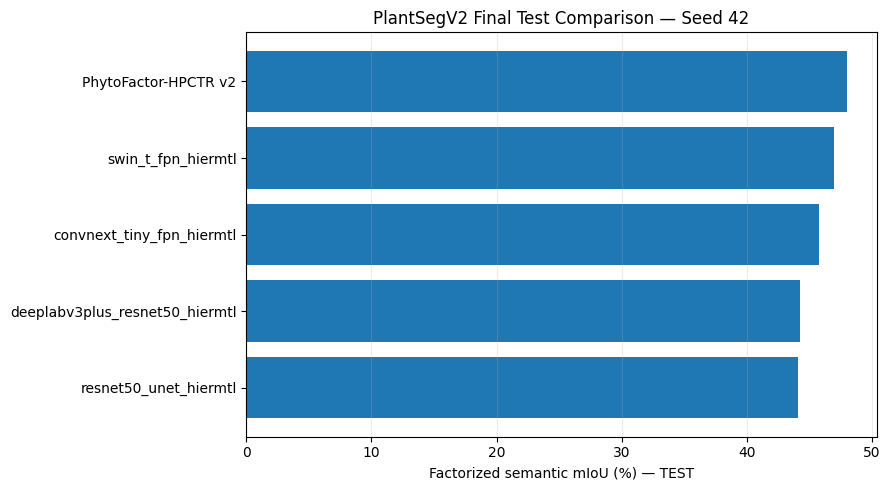

Saved: All Baseline\Baseline_Results\FINAL_TEST_semantic_mIoU_comparison.png


In [41]:

# 18. FINAL comparison plot — only TEST results
runs_df=collect_test_summaries()

if len(runs_df)==0:
    raise RuntimeError(
        "Run at least one baseline first."
    )

plot_df=pd.concat(
    [
        runs_df[
            [
                'model',
                'semantic_miou_disease'
            ]
        ],
        pd.DataFrame([{
            'model':'PhytoFactor-HPCTR v2',
            'semantic_miou_disease':
                HPCTR_V2_TEST_REFERENCE[
                    'semantic_miou_disease'
                ]
        }])
    ],
    ignore_index=True
).sort_values(
    'semantic_miou_disease',
    ascending=True
)

plt.figure(
    figsize=(9,5)
)

plt.barh(
    plot_df['model'],
    plot_df[
        'semantic_miou_disease'
    ]*100
)

plt.xlabel(
    'Factorized semantic mIoU (%) — TEST'
)

plt.title(
    'PlantSegV2 Final Test Comparison — Seed 42'
)

plt.grid(
    axis='x',
    alpha=.25
)

plt.tight_layout()

plot_path=(
    OUTPUT_ROOT
    / 'FINAL_TEST_semantic_mIoU_comparison.png'
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(
    "Saved:",
    plot_path
)
